# Demostración del algoritmo K-NN (K-Nearest Neighbors)

**K-NN** es un clasificador *basado en instancias*: no aprende parámetros durante el entrenamiento, simplemente **memoriza** los datos. Para clasificar un punto nuevo:

1. Calcula la distancia del punto nuevo a **todos** los puntos de entrenamiento (normalmente distancia euclidiana):
   $$d(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}$$
2. Selecciona los **k** puntos más cercanos.
3. Asigna la clase **más votada** entre esos k vecinos.

En este notebook vamos a:
1. Generar datos sintéticos con `make_blobs`.
2. Clasificar un punto **paso a paso a mano** y comprobar que coincide con `sklearn`.
3. Entrenar y evaluar `KNeighborsClassifier`.
4. Ver cómo **k** cambia la frontera de decisión (sobreajuste vs. subajuste).
5. Elegir el mejor **k** con validación cruzada.
6. Analizar el efecto del solapamiento de clases, de la ponderación por distancia y del escalado.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

SEED = 42
COLORES = ["#1f77b4", "#ff7f0e", "#2ca02c"]
CMAP_PUNTOS = ListedColormap(COLORES)
CMAP_FONDO = ListedColormap(["#aec7e8", "#ffbb78", "#98df8a"])
plt.rcParams["figure.dpi"] = 100

## 1. Generación de datos con `make_blobs`

`make_blobs` crea nubes de puntos gaussianas alrededor de unos centros. Parámetros clave:
- `n_samples`: número de puntos.
- `centers`: número de clases, o las coordenadas de sus centros (aquí los fijamos cercanos para que haya solapamiento).
- `cluster_std`: dispersión de cada grupo → a mayor valor, **más solapamiento** y más difícil clasificar.

Forma de X: (300, 2)
Puntos por clase: Counter({np.int64(0): 100, np.int64(2): 100, np.int64(1): 100})


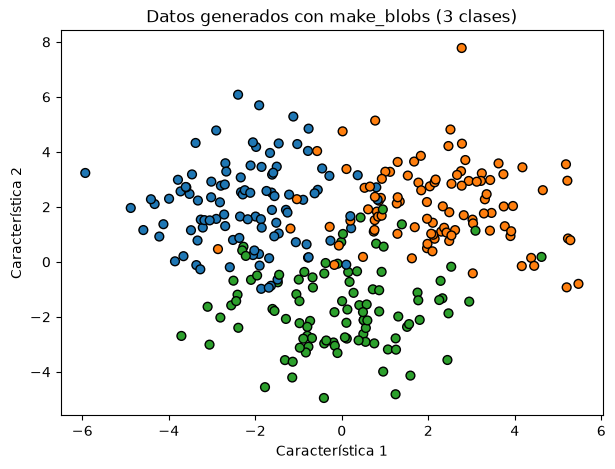

In [2]:
# Centros cercanos a propósito: así las clases se solapan y el problema no es trivial
CENTROS = [[-2, 2], [2, 2], [0, -1.5]]
X, y = make_blobs(n_samples=300, centers=CENTROS, cluster_std=1.5, random_state=SEED)

print("Forma de X:", X.shape)
print("Puntos por clase:", Counter(y))

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=CMAP_PUNTOS, edgecolor="k", s=40)
plt.title("Datos generados con make_blobs (3 clases)")
plt.xlabel("Característica 1"); plt.ylabel("Característica 2")
plt.show()

## 2. División entrenamiento / prueba

Separamos un 30 % de los datos para **evaluar** el modelo con puntos que nunca ha visto. `stratify=y` mantiene la proporción de clases en ambos conjuntos.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y
)
print(f"Entrenamiento: {len(X_train)} puntos | Prueba: {len(X_test)} puntos")

Entrenamiento: 210 puntos | Prueba: 90 puntos


## 3. K-NN paso a paso (implementación manual)

Para entender qué hace realmente el algoritmo, clasificamos **un solo punto nuevo** a mano con k = 5.

In [4]:
k = 5
punto_nuevo = np.array([0.5, 1.0])  # zona de frontera: hay vecinos de varias clases

# Paso 1: distancia euclidiana a TODOS los puntos de entrenamiento
distancias = np.sqrt(((X_train - punto_nuevo) ** 2).sum(axis=1))

# Paso 2: índices de los k más cercanos
idx_vecinos = np.argsort(distancias)[:k]

# Paso 3: votación por mayoría
votos = Counter(y_train[idx_vecinos])
prediccion_manual = votos.most_common(1)[0][0]

print("Los", k, "vecinos más cercanos:")
for i in idx_vecinos:
    print(f"  punto {X_train[i].round(2)}  clase={y_train[i]}  distancia={distancias[i]:.3f}")
print("\nVotos:", dict(votos))
print("Predicción manual:", prediccion_manual)

Los 5 vecinos más cercanos:
  punto [0.74 1.1 ]  clase=1  distancia=0.261
  punto [0.22 1.22]  clase=0  distancia=0.360
  punto [0.79 0.66]  clase=2  distancia=0.448
  punto [0.03 1.01]  clase=2  distancia=0.473
  punto [-0.01  0.72]  clase=2  distancia=0.584

Votos: {np.int64(1): 1, np.int64(0): 1, np.int64(2): 3}
Predicción manual: 2


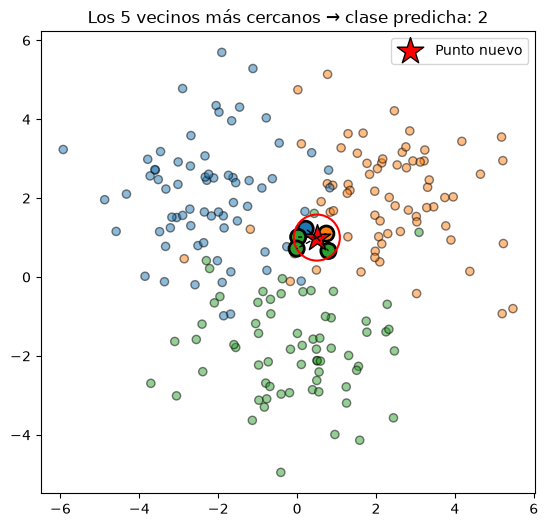

In [5]:
radio = distancias[idx_vecinos[-1]]

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=CMAP_PUNTOS, edgecolor="k", s=35, alpha=0.5)
for i in idx_vecinos:
    ax.plot(*zip(punto_nuevo, X_train[i]), "k--", lw=1)
ax.scatter(X_train[idx_vecinos, 0], X_train[idx_vecinos, 1], c=y_train[idx_vecinos],
           cmap=CMAP_PUNTOS, vmin=0, vmax=2, edgecolor="k", s=120, linewidth=2)
ax.add_patch(plt.Circle(punto_nuevo, radio, fill=False, color="red", lw=1.5))
ax.scatter(*punto_nuevo, marker="*", s=400, c="red", edgecolor="k", label="Punto nuevo")
ax.set_aspect("equal")
ax.set_title(f"Los {k} vecinos más cercanos → clase predicha: {prediccion_manual}")
ax.legend()
plt.show()

### Comprobación con `sklearn`

`KNeighborsClassifier` hace exactamente lo mismo. Verificamos que encuentra **los mismos vecinos** y la **misma predicción**.

In [6]:
knn_demo = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
dist_sk, idx_sk = knn_demo.kneighbors([punto_nuevo])
pred_sk = knn_demo.predict([punto_nuevo])[0]

print("Vecinos sklearn :", sorted(idx_sk[0]))
print("Vecinos manual  :", sorted(idx_vecinos))
print("Predicción sklearn:", pred_sk, "| manual:", prediccion_manual)
print("Probabilidades (fracción de votos):", knn_demo.predict_proba([punto_nuevo])[0])

assert set(idx_sk[0]) == set(idx_vecinos) and pred_sk == prediccion_manual
print("\n✔ La implementación manual coincide con sklearn")

Vecinos sklearn : [np.int64(34), np.int64(72), np.int64(125), np.int64(139), np.int64(146)]
Vecinos manual  : [np.int64(34), np.int64(72), np.int64(125), np.int64(139), np.int64(146)]
Predicción sklearn: 2 | manual: 2
Probabilidades (fracción de votos): [0.2 0.2 0.6]

✔ La implementación manual coincide con sklearn


## 4. Entrenamiento y evaluación del modelo

Usamos un `Pipeline` con `StandardScaler` porque K-NN se basa en **distancias**: si una característica tiene una escala mucho mayor que otra, dominaría el cálculo. (En la sección 8 se demuestra este efecto.)

Exactitud (accuracy) en prueba: 0.844

              precision    recall  f1-score   support

           0      0.800     0.933     0.862        30
           1      0.828     0.800     0.814        30
           2      0.923     0.800     0.857        30

    accuracy                          0.844        90
   macro avg      0.850     0.844     0.844        90
weighted avg      0.850     0.844     0.844        90



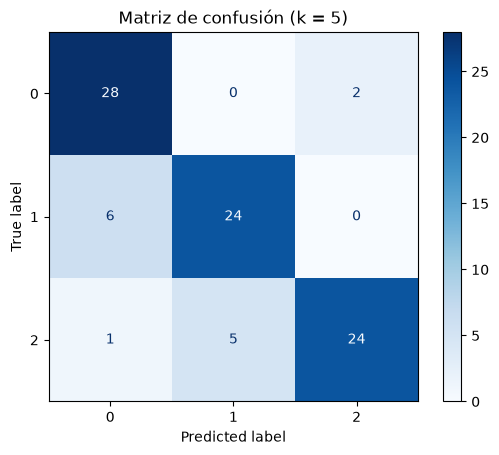

In [7]:
modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

print(f"Exactitud (accuracy) en prueba: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matriz de confusión (k = 5)")
plt.show()

## 5. Fronteras de decisión según k

Pintamos la región que el modelo asigna a cada clase en todo el plano.

- **k pequeño (k=1)**: frontera muy irregular, se adapta a cada punto (incluido el ruido) → **sobreajuste**.
- **k grande**: frontera muy suave, ignora detalles locales → **subajuste**.

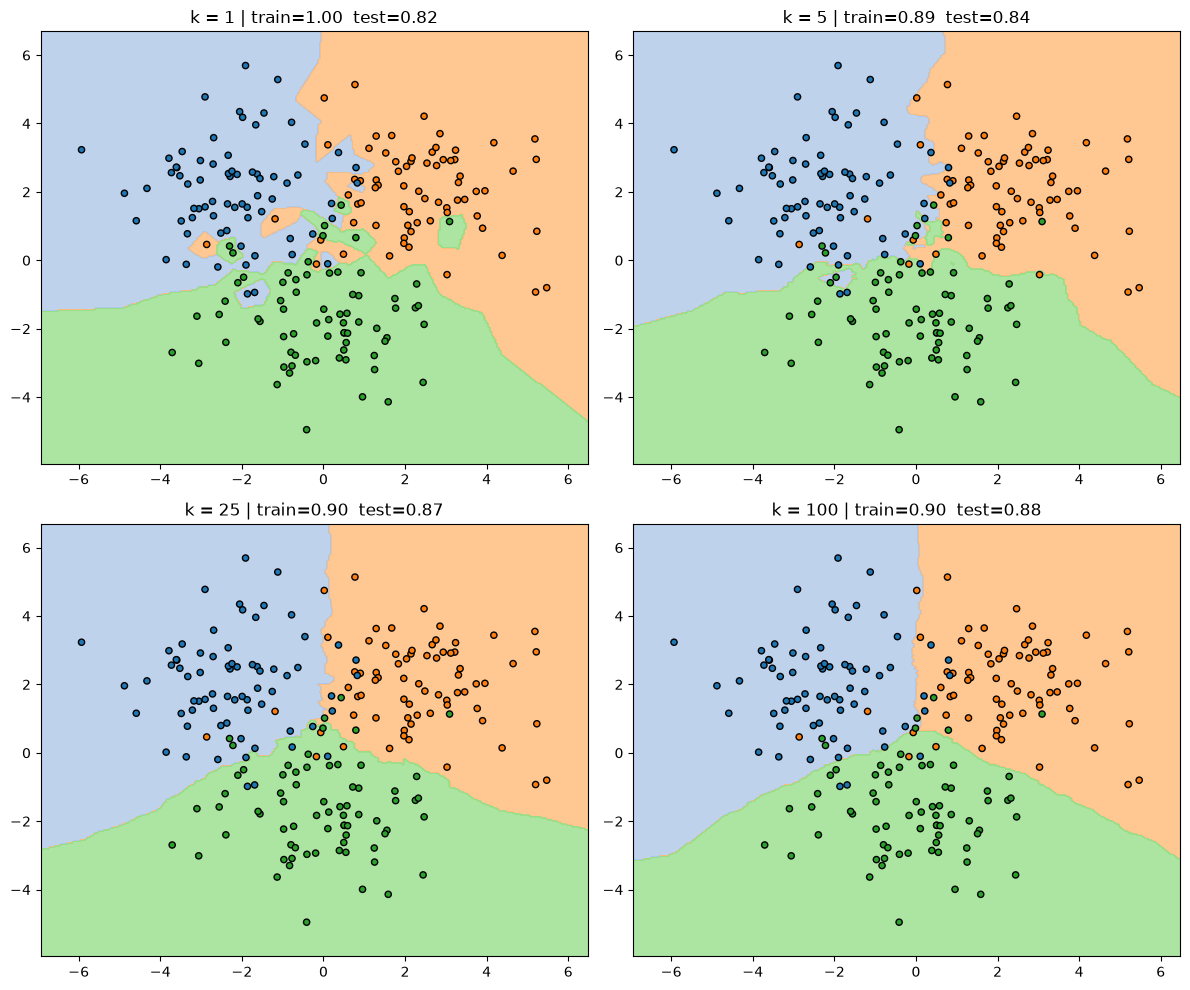

In [8]:
def dibujar_frontera(modelo, X, y, ax, titulo):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=CMAP_FONDO, alpha=0.8)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=CMAP_PUNTOS, edgecolor="k", s=20)
    ax.set_title(titulo)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, k_val in zip(axes.ravel(), [1, 5, 25, 100]):
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_val)).fit(X_train, y_train)
    acc_tr, acc_te = m.score(X_train, y_train), m.score(X_test, y_test)
    dibujar_frontera(m, X_train, y_train, ax, f"k = {k_val} | train={acc_tr:.2f}  test={acc_te:.2f}")
plt.tight_layout()
plt.show()

## 6. Exactitud vs. k: buscando el equilibrio

Con k = 1 la exactitud en **entrenamiento** es 100 % (cada punto es su propio vecino), pero eso no significa que generalice bien. Lo que importa es la exactitud en datos **no vistos**.

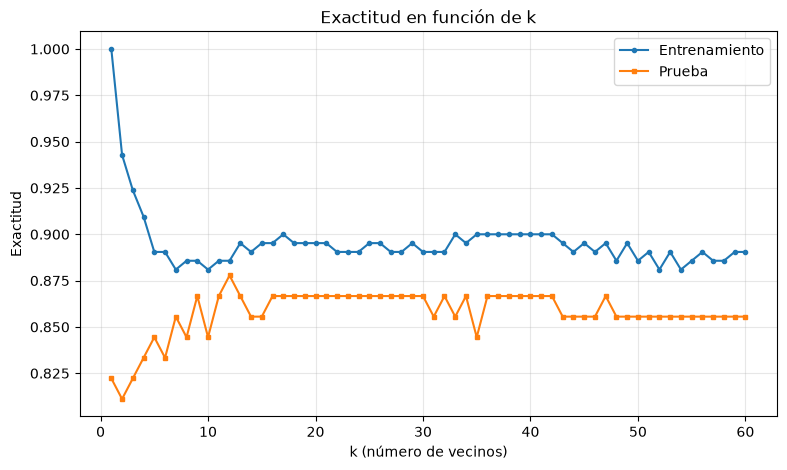

In [9]:
valores_k = range(1, 61)
acc_train, acc_test = [], []
for k_val in valores_k:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_val)).fit(X_train, y_train)
    acc_train.append(m.score(X_train, y_train))
    acc_test.append(m.score(X_test, y_test))

plt.figure(figsize=(9, 5))
plt.plot(valores_k, acc_train, "o-", ms=3, label="Entrenamiento")
plt.plot(valores_k, acc_test, "s-", ms=3, label="Prueba")
plt.xlabel("k (número de vecinos)"); plt.ylabel("Exactitud")
plt.title("Exactitud en función de k")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 7. Selección de k con validación cruzada

Elegir k mirando el conjunto de prueba es "hacer trampa" (estaríamos ajustando al test). Lo correcto es usar **validación cruzada** (5-fold) solo sobre el conjunto de entrenamiento, y evaluar en prueba una única vez al final.

Se suelen probar **k impares** para reducir empates en la votación.

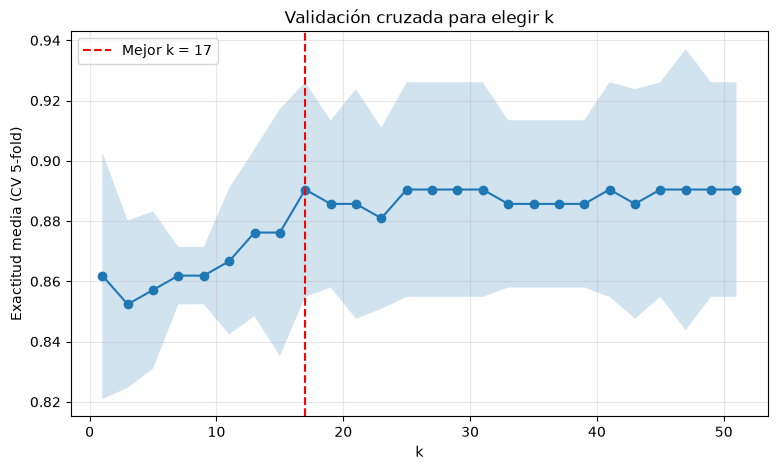

Mejor k según CV: 17  (exactitud CV = 0.890)
Exactitud final en prueba con k=17: 0.867


In [10]:
k_impares = list(range(1, 52, 2))
cv_medias, cv_std = [], []
for k_val in k_impares:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_val))
    scores = cross_val_score(m, X_train, y_train, cv=5)
    cv_medias.append(scores.mean()); cv_std.append(scores.std())

cv_medias, cv_std = np.array(cv_medias), np.array(cv_std)
mejor_k = k_impares[int(np.argmax(cv_medias))]

plt.figure(figsize=(9, 5))
plt.plot(k_impares, cv_medias, "o-")
plt.fill_between(k_impares, cv_medias - cv_std, cv_medias + cv_std, alpha=0.2)
plt.axvline(mejor_k, color="red", ls="--", label=f"Mejor k = {mejor_k}")
plt.xlabel("k"); plt.ylabel("Exactitud media (CV 5-fold)")
plt.title("Validación cruzada para elegir k")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

modelo_final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=mejor_k)).fit(X_train, y_train)
print(f"Mejor k según CV: {mejor_k}  (exactitud CV = {cv_medias.max():.3f})")
print(f"Exactitud final en prueba con k={mejor_k}: {modelo_final.score(X_test, y_test):.3f}")

## 8. Efecto del escalado de características

Multiplicamos la característica 2 por 100. Sin escalar, la distancia depende casi solo de esa característica y K-NN empeora. Con `StandardScaler` el problema desaparece.

In [11]:
X_tr_desesc = X_train * [1, 100]
X_te_desesc = X_test * [1, 100]

sin_escalar = KNeighborsClassifier(n_neighbors=mejor_k).fit(X_tr_desesc, y_train)
con_escalar = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=mejor_k)).fit(X_tr_desesc, y_train)

print(f"Sin escalar : {sin_escalar.score(X_te_desesc, y_test):.3f}")
print(f"Con escalar : {con_escalar.score(X_te_desesc, y_test):.3f}")

Sin escalar : 0.589
Con escalar : 0.867


## 9. Efecto del solapamiento de clases (`cluster_std`)

Cuanto más se solapan los grupos, más difícil es para **cualquier** clasificador. K-NN funciona muy bien con clases bien separadas y su rendimiento cae a medida que aumenta el ruido.

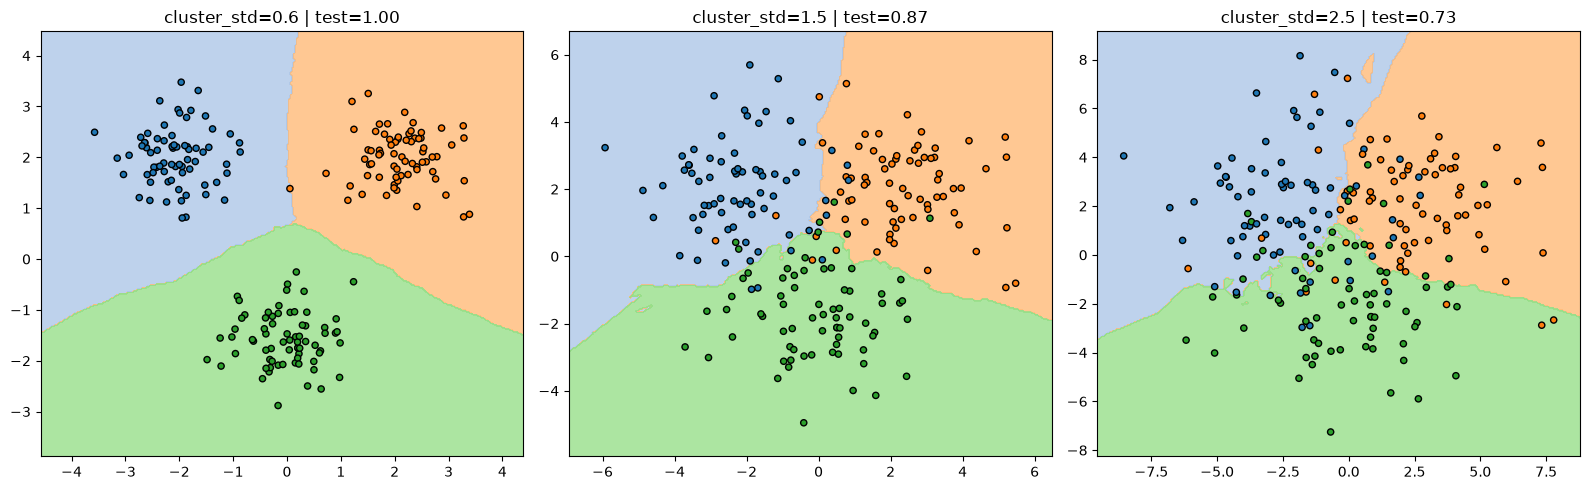

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, std in zip(axes, [0.6, 1.5, 2.5]):
    Xs, ys = make_blobs(n_samples=300, centers=CENTROS, cluster_std=std, random_state=SEED)
    Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=SEED, stratify=ys)
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=mejor_k)).fit(Xs_tr, ys_tr)
    dibujar_frontera(m, Xs_tr, ys_tr, ax, f"cluster_std={std} | test={m.score(Xs_te, ys_te):.2f}")
plt.tight_layout()
plt.show()

## 10. Votación uniforme vs. ponderada por distancia

- `weights="uniform"`: cada vecino vale 1 voto.
- `weights="distance"`: cada vecino vota con peso $1/d$ → los vecinos más cercanos influyen más.

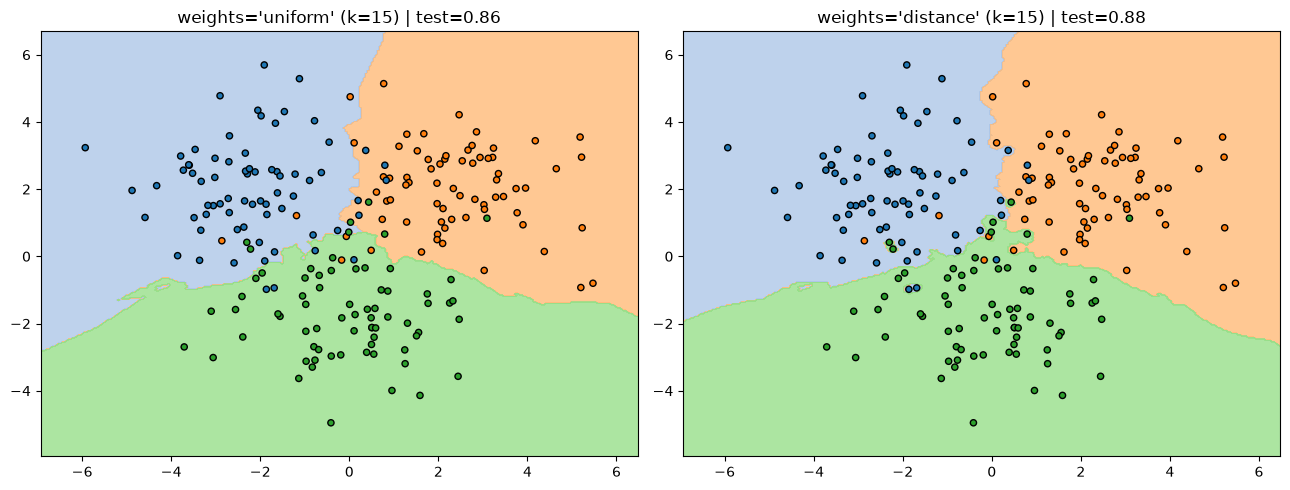

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, w in zip(axes, ["uniform", "distance"]):
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15, weights=w)).fit(X_train, y_train)
    dibujar_frontera(m, X_train, y_train, ax, f"weights='{w}' (k=15) | test={m.score(X_test, y_test):.2f}")
plt.tight_layout()
plt.show()

## 11. Clasificando puntos nuevos

Usamos el modelo final para predecir puntos que no estaban en los datos. `predict_proba` devuelve la fracción de vecinos de cada clase, lo que indica la **confianza** de la predicción (los puntos cerca de una frontera tienen probabilidades repartidas).

Punto [-3.  3.] → clase 0   probabilidades: [1. 0. 0.]
Punto [0.5 1. ] → clase 1   probabilidades: [0.29 0.47 0.24]
Punto [3. 3.] → clase 1   probabilidades: [0. 1. 0.]
Punto [ 0. -3.] → clase 2   probabilidades: [0. 0. 1.]


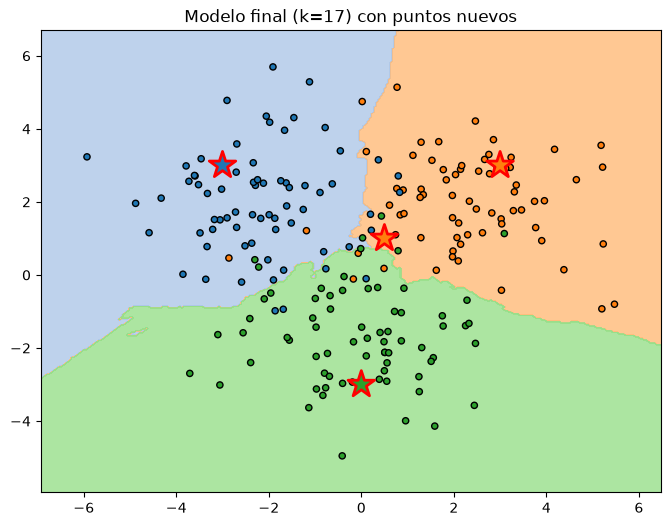

In [14]:
puntos_nuevos = np.array([[-3, 3], [0.5, 1], [3, 3], [0, -3]])
predicciones = modelo_final.predict(puntos_nuevos)
probabilidades = modelo_final.predict_proba(puntos_nuevos)

for p, c, pr in zip(puntos_nuevos, predicciones, probabilidades):
    print(f"Punto {p} → clase {c}   probabilidades: {np.round(pr, 2)}")

fig, ax = plt.subplots(figsize=(8, 6))
dibujar_frontera(modelo_final, X_train, y_train, ax, f"Modelo final (k={mejor_k}) con puntos nuevos")
ax.scatter(puntos_nuevos[:, 0], puntos_nuevos[:, 1], marker="*", s=400,
           c=predicciones, cmap=CMAP_PUNTOS, vmin=0, vmax=2, edgecolor="red", linewidth=2)
plt.show()

## 12. Conclusiones

| Aspecto | Observación |
|---|---|
| **Funcionamiento** | Distancia a todos los puntos → k más cercanos → votación por mayoría. Lo comprobamos a mano y coincide con sklearn. |
| **Elección de k** | k pequeño → sobreajuste (frontera ruidosa); k grande → subajuste (frontera demasiado suave). Se elige con validación cruzada. |
| **Escalado** | Imprescindible: K-NN depende de distancias, y una característica con escala grande domina. |
| **Solapamiento** | Con clases bien separadas K-NN es casi perfecto; con mucho solapamiento ningún k lo arregla. |
| **Ventajas** | Simple, sin entrenamiento, fronteras no lineales, sirve para multiclase de forma natural. |
| **Desventajas** | Predicción lenta con muchos datos (calcula distancias a todos), sensible a la escala y a características irrelevantes, sufre con muchas dimensiones (*maldición de la dimensionalidad*). |